In [1]:
import numpy as np
from itertools import combinations
from time import perf_counter

In [2]:
# taken from https://gist.github.com/danoneata/49a807f47656fedbb389

def fvecs_read(filename, c_contiguous=True):
    """
    reads a file in the fvecs format, returning a 2D numpy array of shape (n, d)
    """
    fv = np.fromfile(filename, dtype=np.float32)
    if fv.size == 0:
        return np.zeros((0, 0))
    dim = fv.view(np.int32)[0]
    assert dim > 0
    fv = fv.reshape(-1, 1 + dim)
    if not all(fv.view(np.int32)[:, 0] == dim):
        raise IOError("Non-uniform vector sizes in " + filename)
    fv = fv[:, 1:]
    if c_contiguous:
        fv = fv.copy()
    return fv

In [3]:
# taken from https://gist.github.com/CharlesLiu7/0496773a8a21934a746e3fd496f11e0c

def ivecs_read(fname):
    a = np.fromfile(fname, dtype='int32')
    d = a[0]
    return a.reshape(-1, d + 1)[:, 1:].copy()

In [4]:
def sim_hash(doc, R):
    sim_hashes = np.dot(doc, R.T) > 0
    return sim_hashes.astype('uint8') #! should be bits

In [5]:
docs = fvecs_read('siftsmall/siftsmall_base.fvecs')
# print(sim_hash(docs[0]))
# print(sim_hash(docs[1]))

In [6]:
def nn_distance(query, data, k=10):
    dist = np.count_nonzero(query != data) #! can be bitwise AND
    if dist <= k:
        return dist
    else:
        return None
    # if dist < k:
    #     return dist

In [7]:
seed = 42
sim_hash_dimension = 64
original_data_dimension = 128

np.random.seed(seed)
R = np.random.randn(sim_hash_dimension, original_data_dimension).astype('float32') # posso farla 1 volta sola e poi riusarla per tutti i documenti

In [8]:
start = perf_counter()
hashes = [sim_hash(d, R) for d in docs]
end = perf_counter()
print(f"Time to compute simhashes: {end - start}")

def close_pairs_generator(hashes, k):
    close_pairs = []
    total_running_time = 0
    for i, j in combinations(range(len(hashes)), 2):
        start = perf_counter()
        result = nn_distance(hashes[i], hashes[j], k=k)
        total_running_time += perf_counter() - start
        if result is not None:
            close_pairs.append((i, j, result))
            # print(f"Distance between index {i} and {j}: {result}")
    
    return close_pairs, total_running_time

close_pairs, total_running_time = close_pairs_generator(hashes, k=2)
print(f"Total running time: {total_running_time}")
print(f"Average running time per pair: {total_running_time / len(close_pairs) if close_pairs else 0}")
print(f"Number of close pairs: {len(close_pairs)}")

Time to compute simhashes: 0.04863179998937994
Total running time: 56.505408437835285
Average running time per pair: 0.03227036461326972
Number of close pairs: 1751


In [8]:
# import matplotlib.pyplot as plt

# k_values = [2, 4, 6, 8, 10, 15, 20]

# num_close_pairs = []
# running_times = []
# close_pairs = [] #! should be a list of lists, one for each k
# for i in k_values:
#     close_pairs_, total_running_time = close_pairs_generator(hashes, k=i)
#     num_close_pairs.append(len(close_pairs_))
#     running_times.append(total_running_time)
#     close_pairs.append(close_pairs_)
#     print(f"k={i}: Total running time: {total_running_time}, Average running time per pair: {total_running_time / len(close_pairs_) if close_pairs_ else 0}, Number of close pairs: {len(close_pairs_)}")

In [9]:
# fig, ax1 = plt.subplots()

# color = 'tab:blue'
# ax1.set_xlabel('k')
# ax1.set_ylabel('Number of close pairs', color=color)
# ax1.plot(k_values, num_close_pairs, marker='o', color=color)
# ax1.tick_params(axis='y', labelcolor=color)

# ax2 = ax1.twinx()
# color = 'tab:red'
# ax2.set_ylabel('Total running time (s)', color=color)
# ax2.plot(k_values, running_times, marker='s', color=color)
# ax2.tick_params(axis='y', labelcolor=color)

# plt.title('Close pairs and running time vs k')
# plt.show()

## Bruteforce Near-Duplicate Detection with SimHash

just a baseline to confront with spark implementation

# banded approach

## spark sanity check

In [9]:
import os
import sys
from pyspark.sql import SparkSession
from pyspark.sql.functions import col

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

spark = (
    SparkSession.builder
    .appName("spark-near-dup-test")
    # .master("spark://didavhpc04:7077")
    .master("local[*]")
    .config("spark.pyspark.python", sys.executable)
    .config("spark.pyspark.driver.python", sys.executable)
    .getOrCreate()
)

print("Driver Python:", sys.executable)
print("Spark version:", spark.version)

# df = spark.createDataFrame([(1, "a"), (2, "b"), (3, "c")], ["id", "letter"])
# result = df.filter(col("id") > 1).orderBy("id").collect()

# print("Result:", result)
# assert [row.id for row in result] == [2, 3]
# assert [row.letter for row in result] == ["b", "c"]

print("Spark is working correctly.")

sc = spark.sparkContext


Driver Python: c:\Python311\python.exe
Spark version: 4.1.1
Spark is working correctly.


In [10]:
def divide_bands(hash, num_bands, doc_id):
    band_size = len(hash) // num_bands
    h = [((hash[i * band_size:(i + 1) * band_size].tobytes(), i), (doc_id, hash.tobytes())) for i in range(num_bands)]
    return h

divide_bands(hashes[0], num_bands=4, doc_id=1)


[((b'\x00\x01\x01\x01\x01\x00\x01\x01\x01\x00\x01\x01\x01\x01\x00\x01', 0),
  (1,
   b'\x00\x01\x01\x01\x01\x00\x01\x01\x01\x00\x01\x01\x01\x01\x00\x01\x01\x01\x01\x00\x01\x01\x01\x00\x00\x01\x01\x01\x01\x00\x01\x00\x00\x00\x00\x01\x00\x00\x00\x01\x01\x00\x00\x01\x00\x00\x00\x01\x00\x00\x00\x00\x01\x00\x00\x01\x01\x00\x01\x00\x01\x00\x01\x00')),
 ((b'\x01\x01\x01\x00\x01\x01\x01\x00\x00\x01\x01\x01\x01\x00\x01\x00', 1),
  (1,
   b'\x00\x01\x01\x01\x01\x00\x01\x01\x01\x00\x01\x01\x01\x01\x00\x01\x01\x01\x01\x00\x01\x01\x01\x00\x00\x01\x01\x01\x01\x00\x01\x00\x00\x00\x00\x01\x00\x00\x00\x01\x01\x00\x00\x01\x00\x00\x00\x01\x00\x00\x00\x00\x01\x00\x00\x01\x01\x00\x01\x00\x01\x00\x01\x00')),
 ((b'\x00\x00\x00\x01\x00\x00\x00\x01\x01\x00\x00\x01\x00\x00\x00\x01', 2),
  (1,
   b'\x00\x01\x01\x01\x01\x00\x01\x01\x01\x00\x01\x01\x01\x01\x00\x01\x01\x01\x01\x00\x01\x01\x01\x00\x00\x01\x01\x01\x01\x00\x01\x00\x00\x00\x00\x01\x00\x00\x00\x01\x01\x00\x00\x01\x00\x00\x00\x01\x00\x00\x00\x00\x01\x00\

In [11]:
def nn_distance_spark(query, data, k=2):
    query = np.frombuffer(query, dtype=np.uint8)
    data = np.frombuffer(data, dtype=np.uint8)
    dist = np.count_nonzero(query != data) #! can be bitwise AND
    if dist <= k:
        return dist
    else:
        return None

In [ ]:
# rdd = sc.parallelize(hashes) # fai map 
rdd = sc.parallelize(docs)
# rdd.zipWithIndex()

shared_matrix = sc.broadcast(R)

candidates = (
    rdd.zipWithIndex()
    .map(lambda h: (sim_hash(h[0], shared_matrix.value), h[1])) # (simhash, doc_id)
    # .map(lambda h: (h[0].tobytes(), h[1],)) 
    .map(lambda h: divide_bands(h[0], num_bands=4, doc_id=h[1]))
    .flatMap(lambda x: x)
    .mapValues(lambda doc_id: [doc_id])
    .reduceByKey(lambda a, b: a + b)
)
# candidates.take(5)

candidate_pairs = (
    candidates
    .flatMap(lambda kv: [tuple(sorted(pair)) for pair in combinations(kv[1], 2)])  # list of (id1,id2)
    .map(lambda pair: (pair, None)) #! questi 2 map potrebbero essere inutili
    .distinct()
    .map(lambda x: x[0])                   # (id1, id2)
    .filter(lambda pair: nn_distance_spark(pair[0][1], pair[1][1], k=2) is not None) #! to uncomment to have the final result without collecting all pairs
)

pairs = candidate_pairs.collect()

print(len(pairs))

# pairs = candidate_pairs.collect()
# # docid + simhash completo invece di broadcast
# results = []
# for i, j in pairs:
#     dist = nn_distance(hashes[i - 1], hashes[j - 1], k=2)
#     if dist is not None:
#         results.append(((i, j), dist))

# results = []
# for (i, hi), (j, hj) in pairs:
#     dist = nn_distance_spark(hi, hj, k=2)
#     if dist is not None:
#         results.append(((i, j), dist))

# print(len(results))

1751


In [14]:
# results = []
# for (i, hi), (j, hj) in pairs:
#     dist = nn_distance_spark(hi, hj, k=2)
#     if dist is not None:
#         results.append(((i, j), dist))

# print(len(results))

In [13]:
def normalize_pair(pair):
    if len(pair) == 3:
        i, j, _ = pair
        return tuple(sorted((i, j)))

    if len(pair) == 2 and isinstance(pair[0], tuple) and isinstance(pair[1], tuple):
        i = pair[0][0]
        j = pair[1][0]
        return tuple(sorted((i, j)))

    i, j = pair
    return tuple(sorted((i, j)))

bf_pairs = {normalize_pair(pair) for pair in close_pairs}
banded_pairs = {normalize_pair(pair) for pair in pairs}

common_pairs = bf_pairs & banded_pairs
bf_only = bf_pairs - banded_pairs
banded_only = banded_pairs - bf_pairs

print("Brute force pairs:", len(bf_pairs))
print("Banded pairs:", len(banded_pairs))
print("Common pairs:", len(common_pairs))
print("Brute force only:", len(bf_only))
print("Banded only:", len(banded_only))
print("Some common pairs:", list(common_pairs)[:10])

Brute force pairs: 1751
Banded pairs: 1751
Common pairs: 1751
Brute force only: 0
Banded only: 0
Some common pairs: [(1545, 2916), (7905, 8335), (439, 6612), (2735, 6160), (7280, 8771), (1458, 1981), (193, 283), (6516, 8115), (4624, 4715), (559, 8370)]


In [23]:
from itertools import combinations
from time import perf_counter
import matplotlib.pyplot as plt

def run_banded_spark_lsh(docs, sim_h_dim ,k=2, num_bands=4, spark=None, original_data_dimension=128, seed=42):
    
    if spark is None:
        print("No Spark session provided")
        return []
    
    # own_spark = spark is None
    # if spark is None:
    #     from pyspark.sql import SparkSession
    #     spark = (
    #         SparkSession.builder
    #         .appName("spark-lsh-run")
    #         .master("local[*]")
    #         .getOrCreate()
    #     )

    timings = {}
    
    np.random.seed(seed)
    R = np.random.randn(sim_h_dim, original_data_dimension).astype('float32') # posso farla 1 volta sola e poi riusarla per tutti i documenti

    sc = spark.sparkContext
    shared_matrix = sc.broadcast(R)

    # def build_candidates(doc_with_id):
    #     doc, doc_id = doc_with_id
    #     h = sim_hash(doc, shared_matrix.value)
    #     return divide_bands(h, num_bands=num_bands, doc_id=doc_id)

    rdd = sc.parallelize(docs)

    candidates = (
        rdd
        .zipWithIndex()
        .map(lambda h: (sim_hash(h[0], shared_matrix.value), h[1])) # (simhash, doc_id)
        .map(lambda h: divide_bands(h[0], num_bands=num_bands, doc_id=h[1]))
        .flatMap(lambda x: x)
        .mapValues(lambda v: [v])
        .reduceByKey(lambda a, b: a + b)
    )

    candidate_pairs = (
        candidates
        .flatMap(lambda kv: [tuple(sorted(pair)) for pair in combinations(kv[1], 2)])
        # .map(lambda pair: (pair, None))
        .distinct()
        # .map(lambda x: x[0])
        .filter(lambda pair: nn_distance_spark(pair[0][1], pair[1][1], k=k) is not None)
    )

    t0 = perf_counter()
    pairs = candidate_pairs.collect()
    timings['total'] = perf_counter() - t0

    # if own_spark:
    #     spark.stop()

    return pairs, timings

In [15]:
def calculate_cosine_similarity(vec1, vec2):
    dot_product = np.dot(vec1, vec2)
    norm_vec1 = np.linalg.norm(vec1)
    norm_vec2 = np.linalg.norm(vec2)
    if norm_vec1 == 0 or norm_vec2 == 0:
        return 0.0
    return dot_product / (norm_vec1 * norm_vec2)

k is the threshold for the Hamming distance to consider two documents as near-duplicates.
sim_h_dim is the dimension of the simhash
num_bands is the number of bands to use in the LSH

1) test how k affects the number of pairs and the running time
2) how does the signature size sim_h_dim affects the running time and quality? ( quality = actual cosine similarity of the pairs found, or number of pairs found if we consider all pairs with cosine similarity > 0.8 as "good" pairs)
3) test how num_bands affects the running time and the quality (same as above)

In [16]:
def plot_results(test_values, all_timings, all_pairs, title_suffix='', xlabel='', ylabel_time='Time (s)', ylabel_pairs='Number of pairs'):
    ks = test_values
    times = [t.get('total', float('nan')) if isinstance(t, dict) else float('nan') for t in all_timings]
    num_pairs = [len(p) for p in all_pairs]

    fig, ax1 = plt.subplots(figsize=(8,4))
    ax1.plot(ks, times, 'o-', color='tab:blue', label='total time (s)')
    ax1.set_xlabel(xlabel)
    ax1.set_ylabel(ylabel_time, color='tab:blue')
    ax1.tick_params(axis='y', labelcolor='tab:blue')

    ax2 = ax1.twinx()
    ax2.plot(ks, num_pairs, 's--', color='tab:red', label='num pairs')
    ax2.set_ylabel(ylabel_pairs, color='tab:red')
    ax2.tick_params(axis='y', labelcolor='tab:red')

    plt.title(f'Banded LSH: time and candidate pairs vs {xlabel}')
    fig.tight_layout()
    plt.show()

In [24]:
all_pairs = []
all_timings = []

test_k_values = [2, 4, 6, 8, 10, 15, 20]

for k in test_k_values:
    print(f"Running banded Spark LSH with k={k}...")
    pairs, timings = run_banded_spark_lsh(docs, sim_h_dim=64, k=k, num_bands=4, spark=spark)
    all_pairs.append(pairs)
    all_timings.append(timings)

Running banded Spark LSH with k=2...
Running banded Spark LSH with k=4...
Running banded Spark LSH with k=6...
Running banded Spark LSH with k=8...
Running banded Spark LSH with k=10...
Running banded Spark LSH with k=15...
Running banded Spark LSH with k=20...


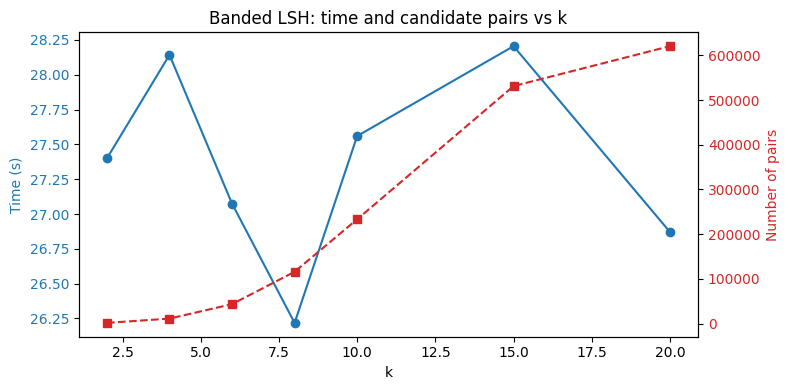

In [25]:
plot_results(test_k_values, all_timings, all_pairs, title_suffix=' (Banded LSH)', xlabel='k')

In [19]:
all_pairs_2 = []
all_timings_2 = []

test_sim_h_dim_values = [32, 64]

for sim_h_dim in test_sim_h_dim_values:
    print(f"Running banded Spark LSH with sim_h_dim={sim_h_dim}...")
    pairs, timings = run_banded_spark_lsh(docs, sim_h_dim=sim_h_dim, k=2, num_bands=min(4, sim_h_dim), spark=spark)
    all_pairs_2.append(pairs)
    all_timings_2.append(timings)

Running banded Spark LSH with sim_h_dim=32...
Running banded Spark LSH with sim_h_dim=64...


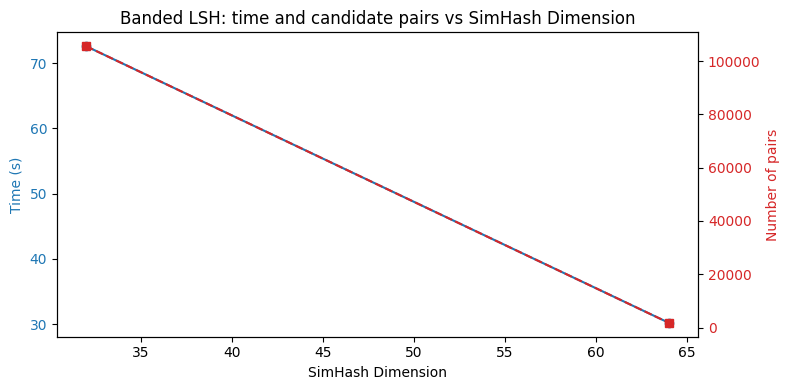

In [ ]:
plot_results(test_sim_h_dim_values, all_timings_2, all_pairs_2, title_suffix=' vs SimHash Dimension', xlabel='SimHash Dimension')

In [21]:
all_pairs_3 = []
all_timings_3 = []

test_num_bands_values = [2, 4]

for num_bands in test_num_bands_values:
    print(f"Running banded Spark LSH with num_bands={num_bands}...")
    pairs, timings = run_banded_spark_lsh(docs, sim_h_dim=64, k=2, num_bands=num_bands, spark=spark)
    all_pairs_3.append(pairs)
    all_timings_3.append(timings)

Running banded Spark LSH with num_bands=2...
Running banded Spark LSH with num_bands=4...


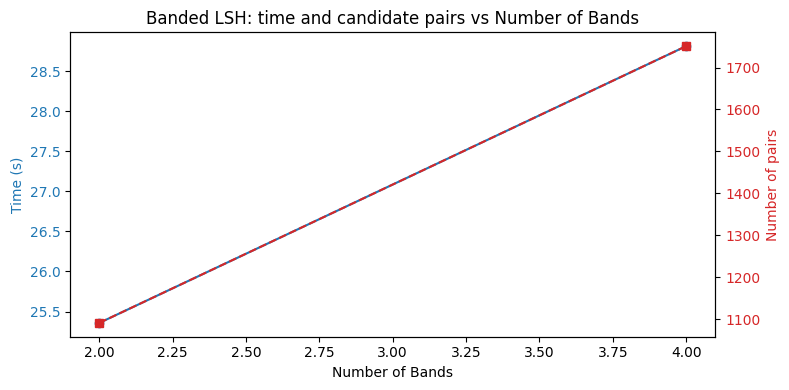

In [ ]:
plot_results(test_num_bands_values, all_timings_3, all_pairs_3, title_suffix=' vs Number of Bands', xlabel='Number of Bands')

In [ ]:
spark.stop()

: 